# Preprocessing review: every keep/remove decision, with its evidence


In [1]:
import os, sys, json
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the project folder (pyproject.toml not found).")
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib; matplotlib.use(os.environ.get("MPLBACKEND", "module://matplotlib_inline.backend_inline"))
import matplotlib.pyplot as plt
from uhi.config import load_configs, get_city, resolve_years
from uhi.preprocess.pipeline import preprocess, load_state

pd.set_option("display.max_colwidth", None); pd.set_option("display.width", 200); pd.set_option("display.max_rows", 200)
RAW_DIR = Path(os.environ.get("UHI_RAW_DIR", ROOT / "data" / "raw"))
OUT_DIR = Path(os.environ.get("UHI_OUT_DIR", ROOT / "data" / "processed"))
pipe, cities = load_configs()
CITY = os.environ.get("UHI_CITY", pipe["city"])
YEARS = resolve_years(pipe, get_city(cities, CITY)) if not os.environ.get("UHI_YEARS") else [int(y) for y in os.environ["UHI_YEARS"].split(",")]
state = load_state(OUT_DIR, CITY)          # reuse the frozen split if scripts/03_preprocess.py has already run
res = preprocess(pipe, CITY, RAW_DIR, YEARS, state=state, expected_years=YEARS)
d, ml, dec = res["clean_df"], res["ml"], pd.DataFrame(res["decisions"])
print(f"{CITY}: years {res['years']} | rows {len(ml)} | kept {len(res['feats'])} features | frozen split reused: {bool(state)}")

delhi: years [2024, 2025, 2026] | rows 4521 | kept 15 features | frozen split reused: True


## 1. Data inventory
One row per cell per year (each year is one composite of its own window: full years, except a still-running year that ends at the latest complete month). A big difference in cells between years would signal an export problem; different month counts mean between-year differences mix season with year.

In [2]:
inv = pd.DataFrame({"raw_rows": res["clean_log"]["rows_in_per_year"], "kept_rows": res["clean_log"]["rows_out_per_year"]})
inv["removed"] = inv.raw_rows - inv.kept_rows
inv = inv.join(d.groupby("year").agg(LST_median=("LST", "median"), SUHII_median=("SUHII", "median"),
                                      SUHII_p05=("SUHII", lambda s: s.quantile(.05)), SUHII_p95=("SUHII", lambda s: s.quantile(.95)),
                                      SUHII_max=("SUHII", "max")))
display(inv.round(2))
if res["provenance"]:
    cols = ["window", "months_in_window", "partial_year", "landsat_scenes_used", "tropomi_window"]
    display(pd.DataFrame(res["provenance"]).T.reindex(columns=cols))
else:
    print("No export log found next to the raw CSVs, so the exact windows are not shown.")

,raw_rows,kept_rows,removed,LST_median,SUHII_median,SUHII_p05,SUHII_p95,SUHII_max
2024,1637,1507,130,36.02,0.58,-1.30,2.97,6.07
2025,1637,1507,130,32.48,0.39,-1.12,2.20,5.46
2026,1637,1507,130,39.84,0.62,-1.17,3.11,6.21


,window,months_in_window,partial_year,landsat_scenes_used,tropomi_window
2024,"[2024-01-01, 2025-01-01]",12,False,77,"[2024-01-01, 2025-01-01]"
2025,"[2025-01-01, 2026-01-01]",12,False,77,"[2025-01-01, 2026-01-01]"
2026,"[2026-01-01, 2026-10-01]",9,True,61,"[2026-01-01, 2026-10-01]"


## 2. Row cleaning
Rows are removed only for missing/placeholder values or mostly-masked cells (`valid_frac < 0.5`). **Hot or cold cells are never removed** (hotspots are what we study). No values are imputed.

In [3]:
pd.DataFrame(res['clean_log']['steps'])

,step,removed,remaining
0,valid_frac < 0.5,390,4521
1,missing target / LST / coordinates,0,4521
2,too many missing features (> 30% of groups),0,4521
3,no donor cell within 3.0 km for a missing feature,0,4521


## 2b. Imputation of missing feature values
A missing FEATURE value is copied from the **nearest cell that has it, in the same year and the same train/test split** (never across the split), only if that cell is within `max_distance_km`; otherwise the row is removed. Rows missing too many features are removed, not repaired. **SUHII (the target) is never imputed.**
The table shows, per feature, how many values were imputed and how far the donors were. `n_imputed` in the final table counts imputed feature groups per row.

In [4]:
il = res["impute_log"]
if il is None:
    print("Imputation is disabled: rows with a missing feature were removed.")
else:
    print({k: v for k, v in il.items() if k != "units"})
    display(pd.DataFrame(il["units"]).T.round(4) if il["units"] else "No missing feature values were found: nothing was imputed.")

{'rule': 'nearest cell with a value, same year, same split', 'max_distance_km': 3.0, 'max_null_share': 0.3, 'rows_before': 4521, 'rows_with_any_missing': 0, 'rows_removed_too_many_missing': 0, 'rows_removed_no_donor_in_range': 0, 'rows_with_imputed_values': 0}


'No missing feature values were found: nothing was imputed.'

## 3. Decision log: what was kept or removed, and why
Every column of the raw export appears here exactly once with its outcome. `final / kept` rows list the VIF and the Spearman correlation with SUHII **as information only**: with the default `priority` rule the target is never used to choose features.

In [5]:
view = dec.assign(metrics=dec.metrics.apply(lambda m: ", ".join(f"{k}={v:.3f}" if isinstance(v, float) else f"{k}={v}" for k, v in m.items())))
view[["feature", "stage", "action", "reason", "metrics"]].sort_values(["action", "stage", "feature"])

,feature,stage,action,reason,metrics
19,DW_crops,dw_reference,dropped,"Reference category for the compositional Dynamic World probabilities (they sum to ~1, so one must go to avoid perfect collinearity). Mean share 0.148; its effect is implicit in the others. Simulations must keep the class shares summing to 1.",mean_share=0.148
20,BSI,spearman,dropped,|rho|=0.987 with NDBI exceeds 0.8; NDBI sits in a higher a-priori priority tier (1 vs 2).,"rho=0.987, kept_instead=NDBI"
24,DW_built,spearman,dropped,"|rho|=0.844 with DW_grass exceeds 0.8; same priority, so the one more correlated with the other remaining features was removed (mean |rho| 0.355 vs 0.341).","rho=-0.844, kept_instead=DW_grass"
23,DW_shrub,spearman,dropped,|rho|=0.851 with DW_built exceeds 0.8; DW_built sits in a higher a-priori priority tier (1 vs 2).,"rho=-0.851, kept_instead=DW_built"
22,NDVI,spearman,dropped,"|rho|=0.852 with DW_trees exceeds 0.8; same priority, so the one more correlated with the other remaining features was removed (mean |rho| 0.301 vs 0.296).","rho=0.852, kept_instead=DW_trees"
21,NDWI,spearman,dropped,|rho|=0.978 with NDVI exceeds 0.8; NDVI sits in a higher a-priori priority tier (1 vs 2).,"rho=-0.978, kept_instead=NDVI"
25,NO2,spearman,dropped,|rho|=0.807 with NTL_log exceeds 0.8; NTL_log sits in a higher a-priori priority tier (2 vs 3).,"rho=0.807, kept_instead=NTL_log"
0,LST,leakage_guard,excluded,SUHII = LST - local rural LST; any LST-derived column would leak the target (spec 8.1).,
1,LST_ref,leakage_guard,excluded,SUHII = LST - local rural LST; any LST-derived column would leak the target (spec 8.1).,
12,DW_label,metadata,excluded,"Identifier / bookkeeping / map-only column, not a physical driver.",


**How the correlated-pair rule works (the part most likely to bias results):** when two features have |Spearman rho| > 0.8, one must go.
With `spearman_keep_rule: priority`, the tiers in `configs/pipeline.yaml` decide (1 = land-surface properties a planner can change, 2 = indirect proxies, 3 = coarse atmosphere/climate).
The tiers are fixed *before* looking at any result, so the outcome (SUHII) cannot steer which variables survive. Inside one tier the data decides (larger mean |rho| to the rest is dropped).
Because the twin must simulate interventions, we prefer to keep the variable an intervention actually changes. A dropped feature's information is still carried by the one that stayed, so **simulations must move correlated features together**.

## 4. Correlation structure (training split, all candidate features before filtering)

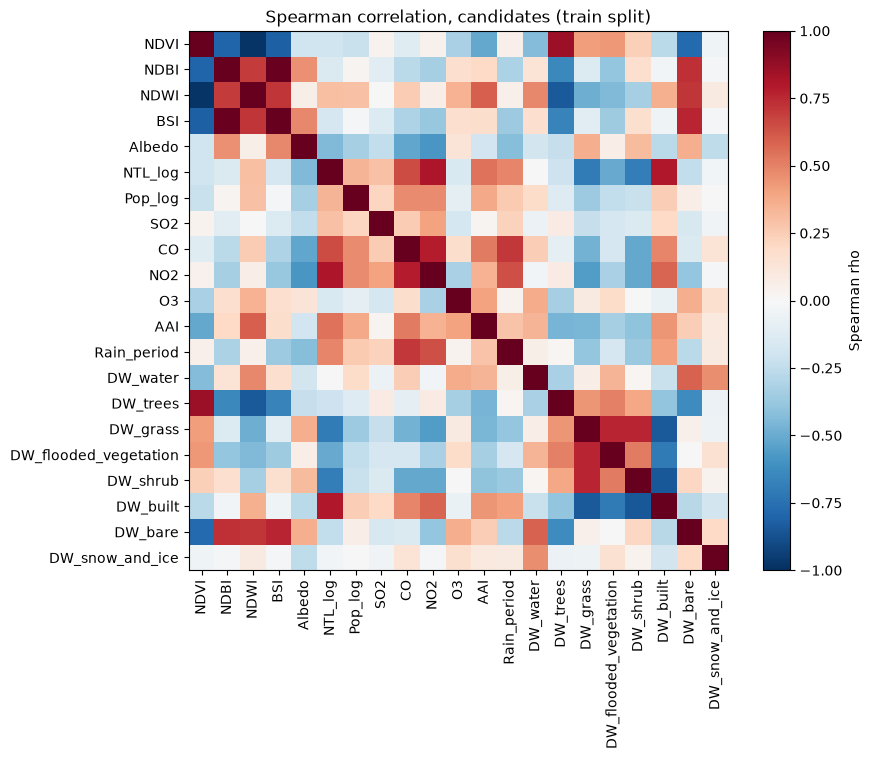

,feature_a,feature_b,rho
3,NDBI,BSI,0.986719
0,NDVI,NDWI,-0.978316
2,NDVI,DW_trees,0.852116
7,DW_shrub,DW_built,-0.850759
6,DW_grass,DW_built,-0.843668
4,NDWI,DW_trees,-0.838867
1,NDVI,BSI,-0.818525
5,NTL_log,NO2,0.807019


In [6]:
cm = res["corr_all"]
fig, ax = plt.subplots(figsize=(9, 7.5)); im = ax.imshow(cm.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=90); ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.index)
plt.colorbar(im, label="Spearman rho"); ax.set_title("Spearman correlation, candidates (train split)"); plt.tight_layout(); plt.show()
pairs = [(a, b, cm.loc[a, b]) for i, a in enumerate(cm.index) for b in cm.columns[i + 1:] if abs(cm.loc[a, b]) > pipe["preprocess"]["spearman_threshold"]]
pd.DataFrame(pairs, columns=["feature_a", "feature_b", "rho"]).sort_values("rho", key=abs, ascending=False)

## 5. Multicollinearity (VIF)
VIF before the Spearman step (candidates) and after all filters (kept). Threshold: 8.

In [7]:
v0 = res["vif_start"].rename("VIF_candidates"); v1 = res["vif_final"].set_index("feature").VIF.rename("VIF_final_kept")
pd.concat([v0, v1], axis=1).sort_values("VIF_candidates", ascending=False).round(2)

,VIF_candidates,VIF_final_kept
NDVI,235.86,NaN
BSI,173.05,NaN
NDWI,147.66,NaN
NDBI,94.18,3.72
DW_built,20.52,NaN
NO2,11.83,NaN
NTL_log,9.06,4.24
CO,8.47,3.75
DW_trees,8.27,2.51
DW_bare,7.39,3.22


## 6. Train/test split
Whole geographic blocks go to one side, and a cell has the same side in every year, so the model is never tested on places it has seen.

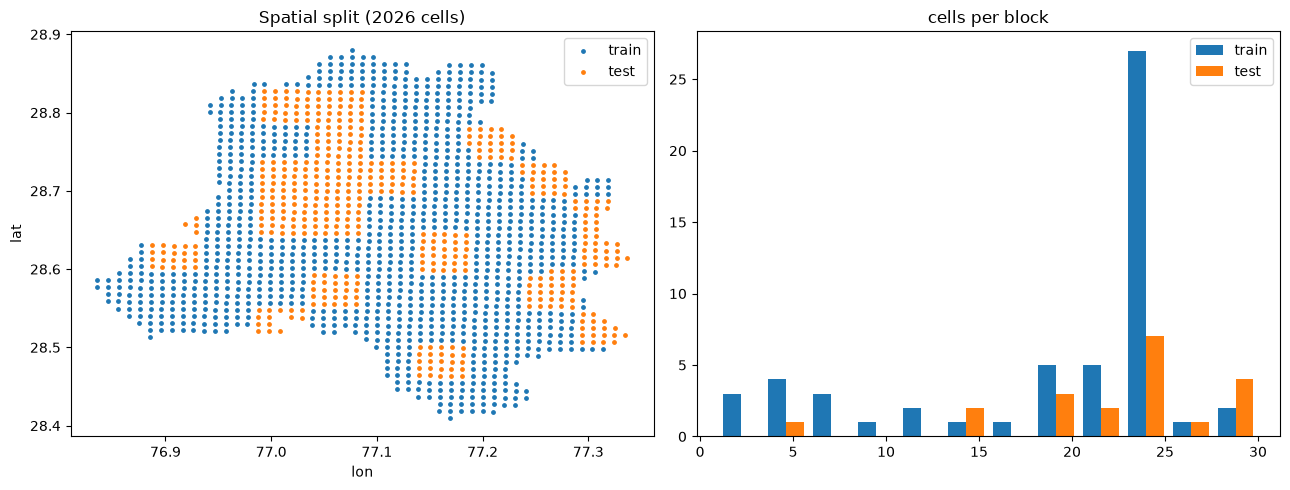

,rows,cells,blocks,SUHII_mean,SUHII_std
split,,,,,
test,1350,450,20,0.48,1.21
train,3171,1057,55,0.69,1.24


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for s, c in (("train", "tab:blue"), ("test", "tab:orange")):
    m = ml[(ml.split == s) & (ml.year == ml.year.max())]; ax[0].scatter(m.lon, m.lat, s=6, c=c, label=s)
ax[0].legend(); ax[0].set_title(f"Spatial split ({ml.year.max()} cells)"); ax[0].set_xlabel("lon"); ax[0].set_ylabel("lat")
bs = ml[ml.year == ml.year.max()].groupby(["split", "block_id"]).size().rename("cells").reset_index()
ax[1].hist([bs[bs.split == s].cells for s in ("train", "test")], label=["train", "test"], bins=12); ax[1].legend(); ax[1].set_title("cells per block")
plt.tight_layout(); plt.show()
ml.groupby("split").agg(rows=("SUHII", "size"), cells=("cell_id", "nunique"), blocks=("block_id", "nunique"),
                        SUHII_mean=("SUHII", "mean"), SUHII_std=("SUHII", "std")).round(2)

## 7. Winsorization (features only; bounds fitted on the train split)
Share of training values clipped should be about 2% (1st + 99th percentile). The target SUHII is never altered.

In [9]:
w = pd.DataFrame(res["winsor_bounds"], index=["lower", "upper"]).T.join(pd.Series(res["winsor_clipped_frac"], name="share_clipped"))
w.round(5)

,lower,upper,share_clipped
NDVI,0.13722,0.56104,0.02018
NDBI,-0.19991,0.05293,0.02018
NDWI,-0.52161,-0.18650,0.02018
BSI,-0.10803,0.11530,0.02018
Albedo,0.12705,0.19080,0.02018
NTL_log,1.35552,4.56275,0.02018
Pop_log,6.78540,10.78744,0.01892
SO2,-0.00008,0.00009,0.02018
CO,-0.00148,0.00196,0.02018
NO2,-0.00004,0.00005,0.02018


## 8. Year-to-year consistency (raw values)
Features listed in `year_center_features` are shown BEFORE centring, because their year-to-year differences are the reason they are centred. A relative change on a mean near 0 (e.g. NDBI) is inflated; read the absolute columns.

In [10]:
raw_of = {c: (c + "__raw" if c + "__raw" in d else c) for c in res["feats"]}      # centred features: show their RAW yearly values
drift = d.groupby("year")[list(raw_of.values()) + ["SUHII"]].mean().T
drift.index = [{v: k for k, v in raw_of.items()}.get(i, i) for i in drift.index]
drift["max_rel_change_%"] = (drift.max(axis=1) - drift.min(axis=1)) / drift.abs().mean(axis=1).replace(0, np.nan) * 100
drift.round(5).sort_values("max_rel_change_%", ascending=False)

year,2024,2025,2026,max_rel_change_%
AAI,0.09125,0.02489,0.20239,167.17030
SO2,0.00019,0.00013,0.00007,86.12365
DW_snow_and_ice,0.08722,0.05798,0.04911,58.84040
SUHII,0.66732,0.45260,0.76103,49.19245
NDBI,-0.05698,-0.07742,-0.05687,32.23135
Rain_period,974.89120,1043.08277,852.16761,19.95530
DW_trees,0.10154,0.12107,0.10141,18.20232
DW_water,0.07022,0.06522,0.06055,14.80121
DW_bare,0.12321,0.10743,0.11407,13.73293
CO,0.04308,0.04088,0.03757,13.61384


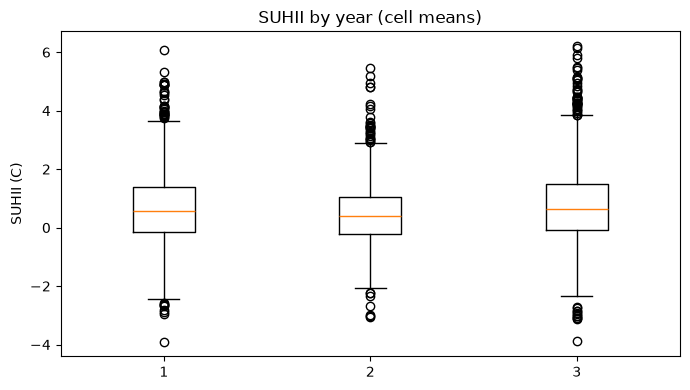

In [12]:
fig, ax = plt.subplots(figsize=(7, 4)); ax.boxplot([ml[ml.year == y].SUHII for y in sorted(ml.year.unique())], label=sorted(ml.year.unique()))
ax.set_ylabel("SUHII (C)"); ax.set_title("SUHII by year (cell means)"); plt.tight_layout(); plt.show()

## 8b. SUHII extremes audit (are the box-plot "outliers" real?)
SUHII outliers are **never removed or clipped** in the dataset: hotspots are what the twin studies. This section checks they are physical, not artefacts.
A real hotspot persists across years and sits on plausible land cover; an artefact (cloud shadow, sliver cell, single bad pixel) would not.

In [13]:
CLS = ["water", "trees", "grass", "flooded_veg", "crops", "shrub", "built", "bare", "snow_ice"]
g = d.groupby("year").SUHII
q1, q3 = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75))
d["is_high_outlier"] = d.SUHII > q3 + 1.5 * (q3 - q1)       # box-plot rule, per year
d["is_low_outlier"] = d.SUHII < q1 - 1.5 * (q3 - q1)
summ = d.groupby("year").agg(cells=("SUHII", "size"), high=("is_high_outlier", "sum"), low=("is_low_outlier", "sum"))
summ["outlier_share_%"] = ((summ.high + summ.low) / summ.cells * 100).round(1)
display(summ)
top = {y: set(x.loc[x.SUHII >= x.SUHII.quantile(.98), "cell_id"]) for y, x in d.groupby("year")}
cold = {y: set(x.loc[x.SUHII <= x.SUHII.quantile(.02), "cell_id"]) for y, x in d.groupby("year")}
n_cells = d.cell_id.nunique()
print(f"Cells in the hottest 2% in EVERY year: {len(set.intersection(*top.values()))}  (pure chance would give about {n_cells * .02 ** len(top):.2f})")
print(f"Cells in the coldest 2% in EVERY year: {len(set.intersection(*cold.values()))}  (pure chance would give about {n_cells * .02 ** len(cold):.2f})")
cols = ["year", "cell_id", "lon", "lat", "SUHII", "LST", "valid_frac", "dominant_class", "NDBI", "NDVI"]
aud = d.assign(dominant_class=d.DW_label.map(dict(enumerate(CLS))))[cols]
print("Hottest 12 cell-years"); display(aud.nlargest(12, "SUHII").round(3))
print("Coldest 12 cell-years"); display(aud.nsmallest(12, "SUHII").round(3))
print("Dominant land cover of the hottest / coldest 2% of cell-years")
display(pd.concat({"hot": aud[aud.SUHII >= aud.SUHII.quantile(.98)].dominant_class.value_counts(normalize=True).round(2),
                   "cold": aud[aud.SUHII <= aud.SUHII.quantile(.02)].dominant_class.value_counts(normalize=True).round(2)}, axis=1))

,cells,high,low,outlier_share_%
year,,,,
2024,1507,34,9,2.9
2025,1507,29,7,2.4
2026,1507,43,12,3.6


Cells in the hottest 2% in EVERY year: 16  (pure chance would give about 0.01)
Cells in the coldest 2% in EVERY year: 14  (pure chance would give about 0.01)
Hottest 12 cell-years


,year,cell_id,lon,lat,SUHII,LST,valid_frac,dominant_class,NDBI,NDVI
3609,2026,703_3160,77.080,28.555,6.209,45.800,1.000,bare,0.037,0.137
3649,2026,704_3159,77.090,28.546,6.152,45.575,1.000,bare,0.051,0.209
595,2024,703_3160,77.080,28.555,6.071,42.562,1.000,bare,0.041,0.118
3608,2026,703_3159,77.080,28.546,5.920,45.273,1.000,bare,0.060,0.229
3651,2026,704_3161,77.091,28.564,5.785,45.976,1.000,built,0.042,0.223
3078,2026,686_3160,76.907,28.558,5.481,46.188,1.000,crops,0.060,0.237
2102,2025,703_3160,77.080,28.555,5.462,38.870,1.000,bare,0.034,0.136
3693,2026,705_3161,77.101,28.564,5.454,45.999,1.000,built,0.049,0.239
3171,2026,691_3157,76.957,28.530,5.398,44.714,1.000,crops,0.036,0.255
76,2024,687_3159,76.917,28.549,5.313,41.153,1.000,crops,0.038,0.255


Coldest 12 cell-years


,year,cell_id,lon,lat,SUHII,LST,valid_frac,dominant_class,NDBI,NDVI
1127,2024,714_3178,77.196,28.716,-3.899,30.950,1.0,trees,-0.179,0.521
4141,2026,714_3178,77.196,28.716,-3.886,34.467,1.0,trees,-0.197,0.546
4415,2026,722_3164,77.275,28.588,-3.113,34.916,1.0,water,-0.230,0.395
4310,2026,718_3176,77.237,28.697,-3.105,34.115,1.0,trees,-0.251,0.615
4299,2026,718_3165,77.234,28.598,-3.085,34.846,1.0,trees,-0.208,0.565
2634,2025,714_3178,77.196,28.716,-3.050,28.532,1.0,trees,-0.174,0.515
3929,2026,710_3166,77.153,28.608,-3.040,34.715,1.0,trees,-0.215,0.610
4313,2026,718_3179,77.237,28.724,-3.022,34.895,1.0,water,-0.209,0.373
2807,2025,718_3180,77.237,28.733,-3.022,27.914,1.0,water,-0.183,0.249
2934,2025,723_3164,77.285,28.588,-2.991,27.812,1.0,water,-0.213,0.343


Dominant land cover of the hottest / coldest 2% of cell-years


,hot,cold
dominant_class,,
crops,0.49,0.16
built,0.31,0.14
bare,0.20,NaN
trees,NaN,0.43
water,NaN,0.26


## 9. Validation gates
`WARN` needs your eyes; `FAIL` blocks use of the dataset; `MANUAL` is yours to confirm (compare LST with published Delhi values).

In [14]:
pd.DataFrame(res['gates'])

,gate,status,detail
0,row_count,PASS,"raw=4911, removed=390, final=4521"
1,nulls,PASS,0 nulls in target+features
2,lst_sanity,PASS,"cell-mean LST 27.8..46.3 C (allowed 10..60); per-year medians 2024: 36.0, 2025: 32.5, 2026: 39.8"
3,suhii_median,PASS,"per-year medians 2024: 0.58, 2025: 0.39, 2026: 0.62 (spec band 0..4 comes from Mumbai - calibrate for this city)"
4,suhii_extremes,PASS,max |SUHII| 6.21 (limit 25)
5,population_max,SKIP,cell-mean Pop max=50719 - set preprocess.expected_pop_max from the GPW source
6,ntl,PASS,NTL_log 1.17..5.19
7,dynamic_world_sum,PASS,100.0% of cell-years have class probabilities summing to 1 +/- 0.05
8,dw_dropped_class_share,PASS,no Dynamic World class dropped up front (only the compositional reference)
9,years_present,PASS,"expected [2024, 2025, 2026], have [2024, 2025, 2026]"


## 10. What the ML stage must respect
* Features for the model = `final_features` in `preprocess_state.json`. `lon`/`lat` only in the labelled spatial-aware variant.
* Cross-validate with **GroupKFold on `block_id`** (never plain K-fold), and keep `split == 'test'` untouched until the end.
* `year` is metadata, not a feature, unless you decide otherwise explicitly.
* Dynamic World shares are compositional: in what-if simulations the class shares must still sum to 1 (the dropped reference class absorbs the remainder).
* Population is the 2020 GPW layer for every year, so it can explain spatial variation but not change over time.